# Lab 19: How to re-engineer a process with agents

## Goal

Decide which steps of a damaged-media refund process are worth automating, set how far each step may act on its own,
and estimate what a redesign is worth. The refund itself stays at **draft**, for a person to approve. The moment that
teaches it is the estimate in Part E: the review and rework a redesign adds eat into the handling time it saves, and
with ten minutes of review per case and one case in ten reworked, the design costs more each month than the time it
frees is worth.

## What you will learn

- How to map a process as visible steps, with the evidence each one needs and the informal handoffs between them.
- How to ask five questions of each step, keeping the path (Q1) apart from the evidence (Q2), and choose a workflow or
  an agent candidate.
- How to set `suggest`, `draft`, `act with audit` or `act` for each step, with a reason.
- How to redesign the work and estimate the capacity it frees and its dollar value, with every assumption visible.
- How to defend a build, buy or neither decision, and apply the same worksheet to a process of your own.

We use Python lists, dictionaries and arithmetic, so every decision and its units can be read directly. There are no
model calls, no API key and no downloads: the one measurement we need, Lab 18's recorded run, is bundled in
`resources/`. This notebook and the worked solution each run on their own.

## Setup

This lab calls no model, so its setup is shorter than the usual config cell: it finds the repository folder by
`models.env`, then this lab's folder and the shop's documents, and reads no settings and no `.env`. `ROOT` is a
`Path`, and `ROOT / "19_Process_Reengineering"` joins folder names without changing the working directory.

In [1]:
from pathlib import Path
import json
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())
LAB = ROOT / "19_Process_Reengineering"
CORPUS = ROOT / "data" / "corpus"
print("Local resources found:", (LAB / "resources/lab18_run_summary.json").is_file())
print("Model calls: 0 | API key required: no")


Local resources found: True
Model calls: 0 | API key required: no


## Part A: Map the process

Before choosing any software, we need to know what a person does today and what evidence each step needs. We follow
one damaged-media case through the whole lab.

First we read the three policies the case touches. The return window, the damaged-twice rule and the refund-payment
clock answer different questions; merging them into one deadline could reject a valid request.

In [2]:
for name in ["policy_returns.md", "policy_damaged_media.md", "policy_refunds.md"]:
    print(name)
    print((CORPUS / name).read_text())


policy_returns.md
# Returns

Physical items (CDs, vinyl, boxed sets) may be returned within 30 days of the invoice date if unopened.

Opened physical media can be returned within 14 days only if the disc is defective. A replacement is preferred over a refund.

Digital downloads and streamed albums cannot be returned. See policy_digital_downloads.md.

Start a return by writing to support. Include the invoice number. Support will reply within the SLA in policy_support_hours.md.

policy_damaged_media.md
# Damaged media

If a CD or vinyl arrives cracked, warped, or will not play, we replace it at no charge. Photograph the damage. Keep the original copy until the replacement arrives, then recycle it.

If the same title arrives damaged twice, offer a refund instead of a third copy.

policy_refunds.md
# Refunds

Refunds go back to the original payment method. They take 5 to 10 business days after support approves the request.

Partial refunds are allowed when only some tracks on a multi-disc 

The damaged-media policy prefers a replacement and offers a refund when the same title arrives damaged twice. The
refunds policy says the money takes **5 to 10 business days after approval**: that is a payment clock, not an
eligibility rule.

Our case is an **illustrative extension** of the shop's data: the same title has arrived damaged twice. It is not a
new fact about ticket 06, whose replacement was shipped. The invoice age, and the handling minutes below, are inputs
we invent for the design exercise. Nothing here issues money or changes a customer record.

In [3]:
case = {
    "case_id": "design-refund-01",
    "invoice_age_days": 10,
    "same_title_damaged_deliveries": 2,
    "photo_present": True,
    "requested_outcome": "refund",
    "payment_status": "not approved",
}
print(json.dumps(case, indent=2))


{
  "case_id": "design-refund-01",
  "invoice_age_days": 10,
  "same_title_damaged_deliveries": 2,
  "photo_present": true,
  "requested_outcome": "refund",
  "payment_status": "not approved"
}


A process is a list of steps in the order they happen. Each step is a dictionary: a stable `id`, the `step` itself,
the `context` (the evidence it needs) and `human_minutes`, a person's active effort for one case (not the customer's
wait for the money). The minutes are assumptions; in a real project you replace them with observed times.

We start with one step. `first_step["context"]` reads its evidence field: what a tool would have to read before we
could automate the step.

In [4]:
first_step = {
    "id": "receive", "step": "Receive and copy the ticket into the refund log",
    "context": "Ticket, invoice reference and photo", "human_minutes": 2.0,
}
print(first_step)
print("Evidence needed:", first_step["context"])


{'id': 'receive', 'step': 'Receive and copy the ticket into the refund log', 'context': 'Ticket, invoice reference and photo', 'human_minutes': 2.0}
Evidence needed: Ticket, invoice reference and photo


Copying the ticket into a refund log is a handoff a support rep does today. A redesign may remove it, but a process
map records the work as it is before judging it. Now the other five steps, and the whole sequence.

In [5]:
process = [
    first_step,
    {"id": "check", "step": "Check the order, return window and damage evidence",
     "context": "Invoice, photo and returns/damaged-media policies", "human_minutes": 3.0},
    {"id": "decide", "step": "Decide replacement or refund eligibility",
     "context": "Delivery history and damaged-media policy", "human_minutes": 4.0},
    {"id": "reply", "step": "Draft the reply with the correct payment clock",
     "context": "Eligibility decision and refunds policy", "human_minutes": 4.0},
    {"id": "refund", "step": "Issue the refund on the original payment method",
     "context": "Approved amount, invoice and original payment record", "human_minutes": 3.0},
    {"id": "close", "step": "Close the ticket after a confirmed payment receipt",
     "context": "Payment receipt and ticket", "human_minutes": 2.0},
]
for row in process:
    print(f"{row['id']:8} | {row['human_minutes']:4.1f} min/case | {row['step']}")
baseline_minutes = sum(row["human_minutes"] for row in process)
print("Baseline human effort:", baseline_minutes, "min/case")


receive  |  2.0 min/case | Receive and copy the ticket into the refund log
check    |  3.0 min/case | Check the order, return window and damage evidence
decide   |  4.0 min/case | Decide replacement or refund eligibility
reply    |  4.0 min/case | Draft the reply with the correct payment clock
refund   |  3.0 min/case | Issue the refund on the original payment method
close    |  2.0 min/case | Close the ticket after a confirmed payment receipt
Baseline human effort: 18.0 min/case


**Checkpoint A.** Six ordered steps and **18.0 human minutes per case**; `sum` adds the `human_minutes` of every row.
That is the baseline of our scenario, not a measurement of what Chinook's staff spend. Next we ask which steps have
enough structure and evidence to change.

---

## Part B: Ask the five questions of each step

Two decisions need keeping apart: what chooses the path through the work, and whether automating it is worth running
at all. Five questions cover both:

| Question | What the answer changes |
|---|---|
| Q1. Can we write the steps down? | Yes: start with a workflow whose branches our code chooses. No: an agent that chooses the next step may be a candidate. |
| Q2. Is the context written down where a tool can read it? | No: fix access or the record before automating the decision. |
| Q3. Is a wrong step recoverable at an acceptable cost? | No: keep the proposed action at draft or below, with a person on the gate. |
| Q4. Does the volume justify building and running it? | No: retain manual work or a checklist; confirm with the calculator. |
| Q5. Will someone own it in six months? | No: assign an owner before building. |

Q1 is about the **path**, Q2 about the **evidence**. Replies worded differently do not by themselves need an agent: a
fixed workflow can use one model call to draft the text. Choosing a workflow does not skip the other questions; we
still ask Q2 to Q5. A step is an agent candidate only with Q1 No and Q2 to Q5 Yes, and even then it must beat a
simpler alternative in a test.

For the check step, the branches are known, the evidence has a named home, and a wrong check can be caught in review.
We assume 1,000 cases a month, and the support operations lead owns the step. The refund step will differ on Q3:
reversing a payment means work for finance and a confused customer.

In [6]:
check_answers = {
    "q1": (True, "Invoice and policy checks have explicit branches."),
    "q2": (True, "Invoice, photo and policies have readable records."),
    "q3": (True, "A reviewer can correct a failed eligibility check before payment."),
    "q4": (True, "Assume 1,000 cases/month; verify the benefit in Part E."),
    "q5": (True, "Support operations lead owns checks and exceptions."),
}
for question, (answer, reason) in check_answers.items():
    print(question, "Yes" if answer else "No", "|", reason)


q1 Yes | Invoice and policy checks have explicit branches.
q2 Yes | Invoice, photo and policies have readable records.
q3 Yes | A reviewer can correct a failed eligibility check before payment.
q4 Yes | Assume 1,000 cases/month; verify the benefit in Part E.
q5 Yes | Support operations lead owns checks and exceptions.


Each value is a pair `(answer, reason)`: a Boolean for the answer and the sentence behind it. `for question, (answer,
reason) in check_answers.items()` unpacks each pair into two names. A bare `True` would hide the business judgement,
so the other five steps get their reasons too.

In [7]:
answers = {"check": check_answers}
step_reasons = {
    "receive": ["Copying known ticket fields is a fixed operation.",
                "Ticket and photo are stored in the support system.",
                "A wrong log entry can be corrected from the original ticket.",
                "Repeated copying across 1,000 cases/month may justify integration.",
                "Support operations lead owns intake."],
    "decide": ["Known policy branches choose replacement or refund.",
               "Delivery history and the policy are available to the reviewer.",
               "A wrong proposal is correctable before approval.",
               "At 1,000 cases/month, test whether the checks reduce handling.",
               "Support policy lead owns eligibility and exceptions."],
    "reply": ["A fixed drafting step receives the decision and policy clock.",
              "Decision and refund policy are recorded inputs.",
              "An unsent draft can be corrected.",
              "At 1,000 cases/month, drafting may save effort after review.",
              "Support policy lead owns templates and reviewed replies."],
    "refund": ["Approved amount, payment method and receipt form a fixed path.",
               "Approval, invoice and payment record must be accessible.",
               "A mistaken payment is costly to reverse; keep a human gate.",
               "Volume may justify preparing a draft, not unreviewed payment.",
               "Finance lead owns approval and reconciliation."],
    "close": ["Close only when the matching payment receipt exists.",
              "The payment system stores the receipt linked to the case.",
              "A ticket can be reopened; the receipt prevents premature closure.",
              "At 1,000 cases/month, avoid repeated status copying.",
              "Support operations lead owns closure checks."],
}
for step_id, reasons in step_reasons.items():
    answers[step_id] = {}
    for number, reason in enumerate(reasons, start=1):
        answer = not (step_id == "refund" and number == 3)
        answers[step_id][f"q{number}"] = (answer, reason)


`enumerate(reasons, start=1)` numbers the five reasons 1 to 5, so each one becomes the reason for Q1 to Q5. Every
answer is Yes except one: `not (step_id == "refund" and number == 3)` makes the refund's Q3 a No. These are our
assumptions about the shop's systems and owners; before a pilot, the real owners confirm them.

We take one step first, the refund: choose its path, and collect its constraints separately. Keeping the two apart is
what lets a known workflow still need a person's approval.

In [8]:
refund_answers = answers["refund"]
path = "workflow" if refund_answers["q1"][0] else "agent candidate"
constraints = []
if not refund_answers["q2"][0]:
    constraints.append("fix context first")
if not refund_answers["q3"][0]:
    constraints.append("human gate; draft or below")
if not refund_answers["q4"][0]:
    constraints.append("volume/cost not justified")
if not refund_answers["q5"][0]:
    constraints.append("assign an owner first")
print("Refund path:", path)
print("Refund constraints:", constraints)


Refund path: workflow
Refund constraints: ['human gate; draft or below']


The refund is a workflow step with a human gate: knowing the steps does not give permission to run them. Now the same
routing for all six steps, as a function. `assess` returns the path and the list of constraints; the Yes and No
answers stay our judgement, not the function's. We print every answer with its reason.

In [9]:
def assess(step_answers):
    path = "workflow" if step_answers["q1"][0] else "agent candidate"
    constraints = []
    if not step_answers["q2"][0]:
        constraints.append("fix context first")
    if not step_answers["q3"][0]:
        constraints.append("human gate; draft or below")
    if not step_answers["q4"][0]:
        constraints.append("volume/cost not justified")
    if not step_answers["q5"][0]:
        constraints.append("assign an owner first")
    return {"path": path, "constraints": constraints}

for row in process:
    result = assess(answers[row["id"]])
    print(row["id"], "|", result["path"], "|", result["constraints"] or "no constraint flagged")
    for question, (answer, reason) in answers[row["id"]].items():
        print(" ", question, "Yes" if answer else "No", "|", reason)


receive | workflow | no constraint flagged
  q1 Yes | Copying known ticket fields is a fixed operation.
  q2 Yes | Ticket and photo are stored in the support system.
  q3 Yes | A wrong log entry can be corrected from the original ticket.
  q4 Yes | Repeated copying across 1,000 cases/month may justify integration.
  q5 Yes | Support operations lead owns intake.
check | workflow | no constraint flagged
  q1 Yes | Invoice and policy checks have explicit branches.
  q2 Yes | Invoice, photo and policies have readable records.
  q3 Yes | A reviewer can correct a failed eligibility check before payment.
  q4 Yes | Assume 1,000 cases/month; verify the benefit in Part E.
  q5 Yes | Support operations lead owns checks and exceptions.
decide | workflow | no constraint flagged
  q1 Yes | Known policy branches choose replacement or refund.
  q2 Yes | Delivery history and the policy are available to the reviewer.
  q3 Yes | A wrong proposal is correctable before approval.
  q4 Yes | At 1,000 cases/

**Checkpoint B.** Six steps, five answers each, and Q1 is Yes for every step: this process is a workflow with known
branches. The refund's Q3 is No, so a person approves the payment. Each printed reason is a claim about access and
ownership that the owners still have to confirm. Next we set how far each step may go inside that workflow.

---

## Part C: Set how far each step may go

Choosing the path does not decide who may act. We set the autonomy of each step separately, whether a script, a
workflow or an agent runs it:

- **suggest:** recommend a next action; a person decides and does it.
- **draft:** prepare the action or the reply, and wait for approval before sending or running it.
- **act with audit:** do a bounded, recoverable action and keep a record anyone can inspect.
- **act:** do a low-stakes action with no routine human gate. It still needs an owner and operating controls.

For this case, a person reviews the eligibility decision and the reply together, and then a person authorised by
finance approves the payment. The notebook only writes these permissions down; it is connected to no payment system.

In [10]:
autonomy = {
    "receive": ("act with audit", "Record intake once and retain the source ticket."),
    "check": ("act with audit", "Run bounded checks; send missing evidence to review."),
    "decide": ("draft", "Prepare eligibility with the rule and evidence for review."),
    "reply": ("draft", "An approved decision must precede a sent promise."),
    "refund": ("draft", "Money leaves; a finance-authorized person approves."),
    "close": ("act with audit", "Close only on a matching payment receipt; retain it."),
}
for row in process:
    level, reason = autonomy[row["id"]]
    print(f"{row['id']:8} | {level:15} | {reason}")


receive  | act with audit  | Record intake once and retain the source ticket.
check    | act with audit  | Run bounded checks; send missing evidence to review.
decide   | draft           | Prepare eligibility with the rule and evidence for review.
reply    | draft           | An approved decision must precede a sent promise.
refund   | draft           | Money leaves; a finance-authorized person approves.
close    | act with audit  | Close only on a matching payment receipt; retain it.


Three steps are `draft` and three are `act with audit`. `close` acts only when the payment receipt exists, not when a
draft does, so the boundary holds even if a draft's text claims the refund was paid.

The `assert` below checks our design for the money step. It cannot enforce a real payment permission: that lives in
the payment tool and its approval system.

In [11]:
assert autonomy["refund"][0] == "draft", "Refund must stay at draft with human approval."
print("✅ Refund preparation waits for human approval.")


✅ Refund preparation waits for human approval.


**Checkpoint C.** You can say why a fixed refund workflow still stops at `draft`, and which evidence lets `close` act.
The labels pay off only when we change the work and its handoffs, which we do next.

---

## Part D: Redesign the process

Now we change the work itself: remove the copying, move the evidence checks before the drafting, and add one explicit
review queue. The redesign below is a proposal for the same damaged-twice case; an exception such as a missing photo
goes to review before anything is promised or paid.

The old process has six steps and the new one five: intake and checks become one step, eligibility and reply drafting
another, and the reviewer gets the evidence and the proposal together. Payment and the receipt-based close stay
separate. The new minutes are assumptions, not a measured speed-up.

In [12]:
redesigned = [
    {"step": "Capture ticket and check evidence once", "autonomy": "act with audit",
     "human_minutes": 1.0, "change": "Remove retyping; route missing evidence before drafting."},
    {"step": "Prepare eligibility and reply with policy evidence", "autonomy": "draft",
     "human_minutes": 1.0, "change": "Reuse the checked record and attach both policies."},
    {"step": "Review decision, wording and payment request", "autonomy": "human review",
     "human_minutes": 2.0, "change": "One queue carries the decision and its evidence."},
    {"step": "Approve and issue payment", "autonomy": "draft until human approval",
     "human_minutes": 3.0, "change": "Keep finance authorization before execution."},
    {"step": "Close only on a matching receipt", "autonomy": "act with audit",
     "human_minutes": 1.0, "change": "Keep the receipt; avoid a second status copy."},
]
for row in redesigned:
    print(f"{row['human_minutes']:3.1f} min/case | {row['autonomy']:26} | {row['step']}")
    print("   ", row["change"])
nonreview_minutes = sum(row["human_minutes"] for row in redesigned if row["autonomy"] != "human review")
review_minutes = sum(row["human_minutes"] for row in redesigned if row["autonomy"] == "human review")
print("Before:", baseline_minutes, "human min/case")
print("After:", nonreview_minutes, "+", review_minutes, "review =", nonreview_minutes + review_minutes, "human min/case")


1.0 min/case | act with audit             | Capture ticket and check evidence once
    Remove retyping; route missing evidence before drafting.
1.0 min/case | draft                      | Prepare eligibility and reply with policy evidence
    Reuse the checked record and attach both policies.
2.0 min/case | human review               | Review decision, wording and payment request
    One queue carries the decision and its evidence.
3.0 min/case | draft until human approval | Approve and issue payment
    Keep finance authorization before execution.
1.0 min/case | act with audit             | Close only on a matching receipt
    Keep the receipt; avoid a second status copy.
Before: 18.0 human min/case
After: 6.0 + 2.0 review = 8.0 human min/case


The estimate falls from **18 to 8 human minutes per case**, before any rework: 6.0 of ordinary handling and 2.0 of
review. The 3 minutes for approving and issuing the payment stay human effort, so the finance gate stays in the count.

In the drawing, read each row from left to right. Lime marks our code and its checks, ink the optional model drafting,
and white the people and the records. The drafting can start with a template; this process needs no second agent.

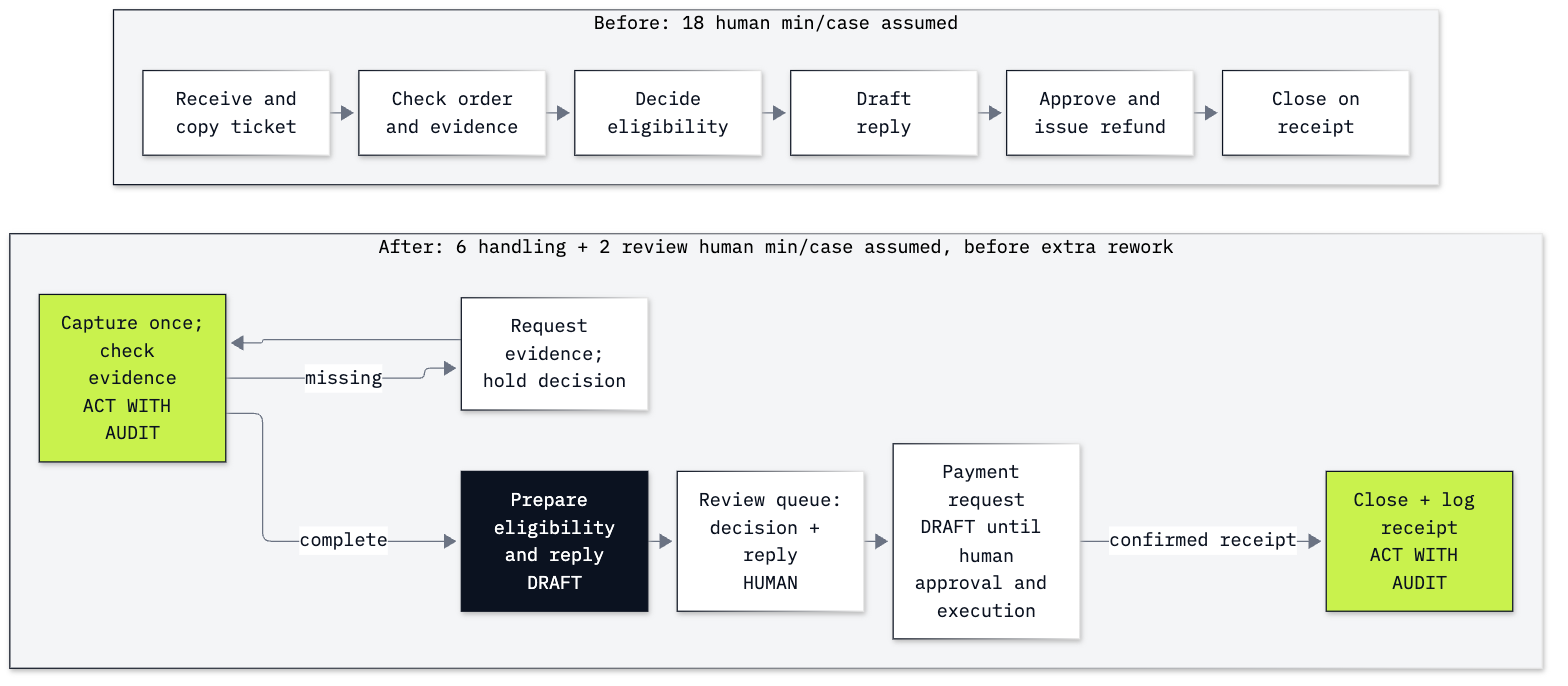

In [13]:
display(Image(filename=str(LAB / "resources/lab19_process_map.png"), width=760))


**Checkpoint D.** Find one removed activity, one check moved earlier and the review queue. The ten minutes saved per
case (twelve of handling, less two of review) still leave out the extra corrections and the system that prepares the
drafts, which Part E pays for.

---

## Part E: Estimate the impact

The estimate needs one measurement, what the model costs per task, and a set of business assumptions that we label as
ours. The measurement is Lab 18's recorded learner run, bundled here as `resources/lab18_run_summary.json`: an
unchanged copy, from source notebook `18_evals_and_tracing.ipynb`, recorded on **2026-11-01**. Lab 18 does not have to
run first.

We read it with Python's [`json`](https://docs.python.org/3/library/json.html) module, which turns a JSON object into
a dictionary. We look at the top-level keys first, then pick `changed`, the run with close-name suggestions.

In [14]:
snapshot = json.loads((LAB / "resources/lab18_run_summary.json").read_text())
print("Snapshot fields:", list(snapshot))
print("Source:", snapshot["source_notebook"], "| recorded:", snapshot["recorded_on"])
measured = snapshot["changed"]
print("Changed measurement:", {key: measured[key] for key in ["tasks", "passed", "pass_rate", "model_calls", "tokens", "cost_per_task_usd"]})
print("Baseline score:", snapshot["baseline"]["passed"], "/", snapshot["baseline"]["tasks"])


Snapshot fields: ['source_notebook', 'recorded_on', 'model', 'reasoning_effort', 'variant', 'prices_per_million_tokens_usd', 'baseline', 'changed', 'limits']
Source: 18_evals_and_tracing.ipynb | recorded: 2026-11-01
Changed measurement: {'tasks': 8, 'passed': 7, 'pass_rate': 0.875, 'model_calls': 20, 'tokens': {'input': 9048, 'cached': 0, 'written': 0, 'output': 581}, 'cost_per_task_usd': 0.0001494125}
Baseline score: 7 / 8


The changed run passed **7/8 = 0.875**, like the baseline, with **20 model calls**, **9,048 input tokens** and **581
output tokens**, and no cached reads or writes. Its cost per task divides by all eight tasks, the failure included.

**Important:** 0.875 is a score on eight teaching cases about lookups and policy, one of them a poem request. It is
**not a measured refund-error rate**, so `1 - 0.875` is not our rework rate. We choose the rework assumption
separately, and vary it.

First we rebuild the token charge from the counts. The snapshot records the prices it used, in US dollars per million
tokens; using them, rather than today's `models.env`, keeps the result reproducible.

In [15]:
tokens = measured["tokens"]
prices = snapshot["prices_per_million_tokens_usd"]
ordinary_input = tokens["input"] - tokens["cached"] - tokens["written"]
token_cost_usd = (
    ordinary_input * prices["PRICE_INPUT_PER_MILLION"]
    + tokens["cached"] * prices["PRICE_CACHED_INPUT_PER_MILLION"]
    + tokens["written"] * prices["PRICE_CACHE_WRITE_PER_MILLION"]
    + tokens["output"] * prices["PRICE_OUTPUT_PER_MILLION"]
) / 1_000_000
cost_per_task_usd = token_cost_usd / measured["tasks"]
print(f"Token charge across the set: ${token_cost_usd:.8f} USD")
print(f"Model-token charge per task: ${cost_per_task_usd:.10f} USD")
assert abs(cost_per_task_usd - measured["cost_per_task_usd"]) < 1e-12
print("✅ Reconstructed charge matches the recorded task average.")


Token charge across the set: $0.00119530 USD
Model-token charge per task: $0.0001494125 USD
✅ Reconstructed charge matches the recorded task average.


**$0.00119530 for the set**, or **$0.0001494125 per task**: the same as the recorded average. That is the token charge
only, with no hosting, review, tax or discounts. A refund case is a different task from Lab 18's questions, so the
scenario assumes one Lab 18 task's worth of model work per case as a stand-in (`token_tasks_per_case`); measure the
real drafting workflow and change it.

### Keep minutes and dollars separate

At 1,000 cases a month, saving ten human minutes a case frees 10,000 minutes a month, before corrections. Suppose one
case in ten (10%) needs twelve extra minutes of correction: that takes 1,200 minutes, and leaves 8,800. This rework is
effort on top of the redesigned handling and review. The 18-minute baseline already holds today's ordinary manual
work, and we do not claim that today's mistakes disappear.

Only then do we turn minutes into hours and multiply by a wage in US dollars an hour: a minute is never subtracted
from a dollar. The scenario works in US dollars throughout: convert your wage to US dollars before entering it.

In [16]:
scenario = {
    "cases_per_month": 1000,
    "before_minutes_per_case": baseline_minutes,
    "after_nonreview_minutes_per_case": nonreview_minutes,
    "review_minutes_per_case": review_minutes,
    "rework_fraction": 0.10,
    "rework_minutes_per_case": 12.0,
    "hourly_wage_usd": 30.0,
    "token_tasks_per_case": 1.0,
    "operations_usd_per_month": 120.0,
    "build_usd": 6000.0,
    "amortization_months": 12,
}
print(json.dumps(scenario, indent=2))


{
  "cases_per_month": 1000,
  "before_minutes_per_case": 18.0,
  "after_nonreview_minutes_per_case": 6.0,
  "review_minutes_per_case": 2.0,
  "rework_fraction": 0.1,
  "rework_minutes_per_case": 12.0,
  "hourly_wage_usd": 30.0,
  "token_tasks_per_case": 1.0,
  "operations_usd_per_month": 120.0,
  "build_usd": 6000.0,
  "amortization_months": 12
}


`rework_fraction` is a business assumption between zero and one, and `rework_minutes_per_case` applies only to that
share of cases. The wage puts a value on the capacity we free; it is not a promise that payroll will fall. `build_usd
/ amortization_months` spreads the one-time build cost over the months we choose, so it can sit beside the monthly
costs; it does not change when the money is paid.

Before packaging the arithmetic, we work out the main case directly. **Predict:** which will take more of the gross
benefit, human review, model tokens or rework?

In [17]:
volume = scenario["cases_per_month"]
gross_minutes = volume * (baseline_minutes - nonreview_minutes)
review_monthly_minutes = volume * scenario["review_minutes_per_case"]
rework_monthly_minutes = volume * scenario["rework_fraction"] * scenario["rework_minutes_per_case"]
net_minutes = gross_minutes - review_monthly_minutes - rework_monthly_minutes
wage_usd_per_hour = scenario["hourly_wage_usd"]
capacity_value_usd = net_minutes / 60 * wage_usd_per_hour
model_monthly_usd = volume * scenario["token_tasks_per_case"] * cost_per_task_usd
build_monthly_usd = scenario["build_usd"] / scenario["amortization_months"]
net_value_usd = capacity_value_usd - model_monthly_usd - scenario["operations_usd_per_month"] - build_monthly_usd
print(f"Gross before review: {gross_minutes:,.0f} min/month")
print(f"Review: {review_monthly_minutes:,.0f} | extra rework: {rework_monthly_minutes:,.0f} min/month")
print(f"Net capacity: {net_minutes:,.0f} min/month = {net_minutes / 60:.2f} hours/month")
print(f"Capacity value: ${capacity_value_usd:,.2f} | model tokens: ${model_monthly_usd:.6f} USD/month")
print(f"Operations: ${scenario['operations_usd_per_month']:.2f} | allocated build: ${build_monthly_usd:.2f} USD/month")
print(f"Net capacity-value estimate: ${net_value_usd:,.2f} USD/month")


Gross before review: 12,000 min/month
Review: 2,000 | extra rework: 1,200 min/month
Net capacity: 8,800 min/month = 146.67 hours/month
Capacity value: $4,400.00 | model tokens: $0.149413 USD/month
Operations: $120.00 | allocated build: $500.00 USD/month
Net capacity-value estimate: $3,779.85 USD/month


Read the lines in order: 12,000 minutes of gross saving (18 − 6 per case, for 1,000 cases), minus 2,000 of review and
1,200 of rework, leaves **8,800 minutes a month**, or 146.67 hours, worth **$4,400.00 a month** at $30 an hour. Then
we subtract the model tokens (about $0.15), operations ($120.00) and the build spread over twelve months ($500.00):
**$3,779.85 a month**. Review takes more than rework here, and both are worth far more than the tokens. **The tokens
are the cheap part; people's time decides the result.** Only a pilot that measures handling, review, the correction
rate and adoption can confirm these savings.

Now we wrap the same arithmetic in `estimate`, so that changing one assumption recomputes everything that depends on
it. It returns named fields with their units in the names. Below, `dict.copy()` gives a separate dictionary of
assumptions: changing a number in the copy leaves the base scenario untouched.

In [18]:
def estimate(s):
    volume = s["cases_per_month"]
    net_minutes = volume * (
        s["before_minutes_per_case"] - s["after_nonreview_minutes_per_case"]
        - s["review_minutes_per_case"] - s["rework_fraction"] * s["rework_minutes_per_case"]
    )
    wage_usd = s["hourly_wage_usd"]
    capacity_usd = net_minutes / 60 * wage_usd
    model_usd = volume * s["token_tasks_per_case"] * cost_per_task_usd
    fixed_usd = s["operations_usd_per_month"] + s["build_usd"] / s["amortization_months"]
    return {"net_minutes_per_month": net_minutes, "capacity_value_usd_per_month": capacity_usd,
            "model_usd_per_month": model_usd, "fixed_usd_per_month": fixed_usd,
            "net_value_usd_per_month": capacity_usd - model_usd - fixed_usd}

print(estimate(scenario))


{'net_minutes_per_month': 8800.0, 'capacity_value_usd_per_month': 4400.0, 'model_usd_per_month': 0.14941250000000003, 'fixed_usd_per_month': 620.0, 'net_value_usd_per_month': 3779.8505875}


The dictionary matches the direct calculation, field by field (`fixed_usd_per_month` is the $120 of operations plus
the $500 of build). `estimate` takes review and rework as inputs; it does not infer either from Lab 18's score.

### When does review consume the benefit?

A sensitivity table changes the uncertain inputs and keeps the rest fixed. Each row is one assumed future: the review
minutes apply to every case, and the rework share to the cases that need an extra correction. Negative minutes mean
the design uses more human time than the baseline; negative dollars mean the capacity it frees is worth less than the
system costs.

In [19]:
print("review min/case | rework share | net min/month | net USD/month")
for review in [2.0, 6.0, 10.0]:
    for rework in [0.0, 0.1, 0.3, 0.5]:
        trial = scenario.copy()
        trial["review_minutes_per_case"] = review
        trial["rework_fraction"] = rework
        result = estimate(trial)
        print(f"{review:15.1f} | {rework:11.0%} | {result['net_minutes_per_month']:13,.0f} | {result['net_value_usd_per_month']:13,.2f}")


review min/case | rework share | net min/month | net USD/month
            2.0 |          0% |        10,000 |      4,379.85
            2.0 |         10% |         8,800 |      3,779.85
            2.0 |         30% |         6,400 |      2,579.85
            2.0 |         50% |         4,000 |      1,379.85
            6.0 |          0% |         6,000 |      2,379.85
            6.0 |         10% |         4,800 |      1,779.85
            6.0 |         30% |         2,400 |        579.85
            6.0 |         50% |             0 |       -620.15
           10.0 |          0% |         2,000 |        379.85
           10.0 |         10% |           800 |       -220.15
           10.0 |         30% |        -1,600 |     -1,420.15
           10.0 |         50% |        -4,000 |     -2,620.15


At ten minutes of review and 10% rework the design still frees **800 minutes a month**, but the net value is
**−$220.15 a month** after the system costs. At six minutes of review and 50% rework it frees nothing and costs
**$620.15 a month**. Saving handling time is not, on its own, a reason to build.

Now the break-even review time in the base scenario. From the per-case minutes the redesign saves, we subtract the
assumed rework, then the minutes of wages that would pay the fixed and token costs. What is left is the most review
time per case the design can afford, under our assumptions.

In [20]:
base_result = estimate(scenario)
cost_minutes_per_case = (
    (base_result["fixed_usd_per_month"] + base_result["model_usd_per_month"])
    / wage_usd_per_hour * 60 / scenario["cases_per_month"]
)
review_limit = (
    baseline_minutes - nonreview_minutes
    - scenario["rework_fraction"] * scenario["rework_minutes_per_case"]
    - cost_minutes_per_case
)
print(f"Break-even review effort: {review_limit:.2f} min/case")


Break-even review effort: 9.56 min/case


**9.56 minutes** of review per case is the break-even: below it the design is worth more than it costs, above it less,
which matches the table (positive at 6 minutes and 10% rework, negative at 10).

**Checkpoint E.** The base result is **8,800 min/month** and **$3,779.85 a month**, with a break-even review time of
**9.56 min/case** at the chosen wage and costs. You can say why Lab 18's 0.875 pass rate cannot replace the rework
assumption. A pilot must also record the losses this effort-only calculator leaves out: a wrong payout, harm to a
customer, queue delays and compliance work.

---

## Part F: Decide build, buy or neither

A positive estimate is a hypothesis to test, not a reason to build a custom agent. For this process the path is known,
so we start with the workflow and its payment gate, and with a template before paying for model drafting.

| Option | What we would obtain | Evidence needed before choosing |
|---|---|---|
| Build | A small workflow around existing records, checks, review queue and payment authorization | Tool access, a named support/finance owner, observed review effort, maintenance capacity |
| Buy | A support platform feature that performs the same bounded work | A real quote, record access, approval controls, exportable audit records, pilot quality on our cases |
| Neither | Keep the manual checklist and improve evidence capture | Low volume, unavailable context, no owner or costs greater than the usable capacity |

We can compare prices with made-up figures without turning them into claims about a vendor. Suppose a bought feature
costs $900 a month, plus $300 a month for integration and support. We keep the build scenario's review and rework
**only to isolate the price**; a real purchase must measure them again, and check whether the quote includes model
tokens.

In [21]:
buy = scenario.copy()
buy["operations_usd_per_month"] = 900.0 + 300.0
buy["build_usd"] = 0.0
for label, assumptions in [("Build", scenario), ("Buy (illustrative)", buy)]:
    result = estimate(assumptions)
    print(f"{label:20} | net capacity value: ${result['net_value_usd_per_month']:,.2f} USD/month")
print("Neither: keep the manual baseline; no incremental system cost or released capacity is claimed.")


Build                | net capacity value: $3,779.85 USD/month
Buy (illustrative)   | net capacity value: $3,199.85 USD/month
Neither: keep the manual baseline; no incremental system cost or released capacity is claimed.


Build comes to **$3,779.85** a month and the illustrative buy to **$3,199.85**: the $580 between them comes only from
the assumed system costs, and says nothing about a vendor's quality, security or running effort. Both value all the
freed time at the wage; it becomes cash only through a real staffing or redeployment decision.

**Checkpoint F.** Our provisional recommendation is a small workflow pilot with human approval: not a custom agent,
and not several agents. We would reconsider buying if a real quote and a pilot gave a better total result, and choose
neither if the ownership, the evidence or the value cannot be established.

---

## Part G: Apply it to your own process

Now the same decisions on work you know. First state the business problem in one sentence, and ask yourself twice:
what problem would this automation solve? Then map the informal handoffs as well as the system steps.

**Working alone:** take one process you do yourself and play both roles: propose the change, then reread it as the
person who must handle its mistakes. If you cannot use a work example, keep the damaged-media case and look at a
missing-photo exception. With a partner, swap maps and ask them to challenge each evidence source and the cost of a
wrong step.

The row below is that fallback example. `context_available` is our judgement, written down; we do not guess it from
words in a description. Here the photo has not arrived, so the workflow must ask for it before any eligibility
decision.

In [22]:
my_process = [{
    "step": "Assess a damaged-media request with no photo attached",
    "context_lives": "Support ticket, invoice and policy; photo still with customer",
    "context_available": False,
    "wrong_step_costs": "Incorrect eligibility can promise an unjustified refund",
    "autonomy": "suggest",
    "owner": "Support operations lead",
    "next_action": "Request the photo; hold eligibility and payment for review",
}]
print(json.dumps(my_process[0], indent=2))


{
  "step": "Assess a damaged-media request with no photo attached",
  "context_lives": "Support ticket, invoice and policy; photo still with customer",
  "context_available": false,
  "wrong_step_costs": "Incorrect eligibility can promise an unjustified refund",
  "autonomy": "suggest",
  "owner": "Support operations lead",
  "next_action": "Request the photo; hold eligibility and payment for review"
}


One row shows both the missing evidence and what to do about it. It also keeps Q2 apart from Q1: the steps for asking
for a photo are known, but the photo itself is not available.

Replace the fallback row with your own rows, and add Q1 to Q5 answers with plain reasons, as in Part B. For each row,
record the source a tool would read, who owns the work, what a mistake costs and the autonomy you choose. Then copy
`scenario`, put in your own volume and effort, and work out at least one pessimistic alternative. Keep private
customer data out of the worksheet.

In [23]:
for row in my_process:
    print(row["step"], "|", row["autonomy"], "| owner:", row["owner"])
    if not row["context_available"]:
        print("Context blocked:", row["context_lives"])
    print("Next action:", row["next_action"])


Assess a damaged-media request with no photo attached | suggest | owner: Support operations lead
Context blocked: Support ticket, invoice and policy; photo still with customer
Next action: Request the photo; hold eligibility and payment for review


**Checkpoint G.** The fallback row has one blocked context and a concrete next action: ask for the evidence before
deciding. Your finished worksheet holds a process map, five explained answers per step, the autonomy of each step, a
before-and-after proposal, an impact estimate with its units, and a build, buy or neither recommendation. Deciding
that the process should stay manual is a complete outcome when the reasons support it.

## What you can do now

- Map a process with its evidence and handoffs, and keep a known path (Q1) apart from evidence a tool can read (Q2)
  (Parts A and B).
- Set the autonomy of each step, and keep a person's approval on payment (Part C).
- Remove handoffs and move checks earlier in a redesign (Part D).
- Estimate the capacity a redesign frees and its dollar value without mixing minutes and dollars, or treating a
  teaching score as a production error rate (Part E).
- Carry the five questions and an editable estimate into a build, buy or neither decision (Parts F and G).

## Challenge

Use the same damaged-media process. The worked answer below repeats every setup step and part above, so this notebook
runs from a clean kernel.

1. Copy `scenario`. Set review to **6 min/case** and the illustrative rework fraction to **0.30**. Work out the
   monthly capacity and net value, then explain whether positive minutes alone justify the design. Keep the refund at
   `draft`.
2. Copy the refund's five answers. Assume the original payment record is inaccessible: change Q2 and its reason, run
   `assess`, and say what must happen before automation goes ahead. A known path must still be reported as a workflow,
   with the context and human-gate constraints.
3. Write a two-sentence decision for the changed process: who owns fixing the evidence, and whether you would build,
   buy or do neither before that fix. Name one measurement that could change the decision.

Expected outcomes: the first result stays positive in both minutes and dollars, but below the base result. The second
blocks automation on context and keeps the refund gate. Together they check the calculator and the difference between
Q1, Q2 and Q3.

In [24]:
challenge_scenario = scenario.copy()
challenge_scenario["review_minutes_per_case"] = 6.0
challenge_scenario["rework_fraction"] = 0.30
challenge_result = estimate(challenge_scenario)
print(json.dumps(challenge_result, indent=2))
print("Refund autonomy:", autonomy["refund"][0])
assert abs(challenge_result["net_minutes_per_month"] - 2400) < 1e-8
assert abs(challenge_result["net_value_usd_per_month"] - 579.8505875) < 1e-8
assert autonomy["refund"][0] == "draft"
print("✅ The changed estimate and the payment boundary match the challenge.")


{
  "net_minutes_per_month": 2400.0000000000005,
  "capacity_value_usd_per_month": 1200.0000000000002,
  "model_usd_per_month": 0.14941250000000003,
  "fixed_usd_per_month": 620.0,
  "net_value_usd_per_month": 579.8505875000003
}
Refund autonomy: draft
✅ The changed estimate and the payment boundary match the challenge.


The changed design frees **2,400 min/month**, worth **$1,200.00 a month** at the assumed wage, and nets **$579.85 a
month**, below the base result. The printed `2400.0000000000005` is a float's rounding remainder, so the checks allow
a tolerance of `1e-8`. The arithmetic stays positive, but unavailable payment evidence can still stop the
implementation: an estimate cannot grant permission to pay.

Now Q2. We copy the five answers with `.copy()`. Each is a Boolean-and-reason pair, so replacing the whole Q2 pair
changes the copy and leaves the original alone. Q1 stays Yes and Q3 stays No.

In [25]:
challenge_answers = answers["refund"].copy()
challenge_answers["q2"] = (False, "The original payment record is inaccessible to the proposed tool.")
print("Changed Q2:", challenge_answers["q2"])
challenge_assessment = assess(challenge_answers)
print(challenge_assessment)
assert challenge_assessment["path"] == "workflow"
assert challenge_assessment["constraints"] == ["fix context first", "human gate; draft or below"]
assert answers["refund"]["q2"][0] is True
print("✅ The workflow is blocked on evidence and still requires approval.")


Changed Q2: (False, 'The original payment record is inaccessible to the proposed tool.')
{'path': 'workflow', 'constraints': ['fix context first', 'human gate; draft or below']}
✅ The workflow is blocked on evidence and still requires approval.


Two independent constraints: fix the context first, and keep a person on the payment approval. The original assessment
still has Q2 Yes, so the challenge copy did not change it.

**Worked decision:** neither build nor buy a payment-automation feature until the finance lead gives the tool
authorised access to the original payment record and the support operations lead defines the exception queue. After
that fix, pilot a workflow with draft payment requests, measure review effort and extra corrections on real cases, and
compare the result, and a real platform quote, with the positive but assumption-dependent estimate of $579.85 a month.

Another decision can be defensible too, such as a manual checklist at low volume or an existing platform for lower
maintenance. It must still name the missing evidence, the owner and the payment gate.

## Resources

- [Python data structures](https://docs.python.org/3/tutorial/datastructures.html): dictionaries, lists and ordered
  iteration.
- [Python JSON](https://docs.python.org/3/library/json.html): reading the recorded snapshot.
- [Python copies](https://docs.python.org/3/library/copy.html): when a shallow or deep copy is needed.
- [NIST AI Risk Management Framework](https://airc.nist.gov/airmf-resources/airmf/): a broader risk-management
  reference for governance, context, measurement and ongoing management.
- [Resource provenance](../resources/README.md): policy sources, the recorded measurement, its fields and its limits.